In [51]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
gam_gr = pd.read_csv("/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/Pseudotime/Figures/GAM_pseudoprogression_groups.csv", index_col=0)

In [53]:
lr_df = pd.read_csv("/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/CellCellComms/CCC_results/cluster_LR_pairs_all_classes_edgesig.csv")

In [ ]:
trend_dict = {0: "Increasing", 1: "Decreasing"}
gam_gr["Trend"] = gam_gr["TrendGroup"].map(trend_dict)

In [55]:
agm_trend = dict(zip(gam_gr["Cluster"], gam_gr["Trend"]))

In [57]:
lr_sig = lr_df[(lr_df["directionality"] == "Ligand-Receptor") ].copy()

In [61]:
lr_sig = lr_sig[
    (lr_sig["sender_cluster"] != lr_sig["receiver_cluster"]) &
    (lr_sig["significant_AGM_edge"] == True)
].copy()

In [62]:
lr_sig["sender_trend"] = lr_sig["sender_cluster"].map(agm_trend)

lr_sig["receiver_trend"] = lr_sig["receiver_cluster"].map(agm_trend)

In [63]:
lr_sig["trajectory_pair"] = (
    lr_sig["sender_trend"] + " -> " + lr_sig["receiver_trend"]
)

In [64]:
lr_sig["trajectory_pair"].value_counts()

trajectory_pair
Decreasing -> Increasing    10
Increasing -> Decreasing     8
Increasing -> Increasing     8
Decreasing -> Decreasing     3
Name: count, dtype: int64

In [65]:
observed_cross = (
    lr_sig["sender_trend"] != lr_sig["receiver_trend"]
).sum()

observed_cross

18

In [66]:
n_perm = 10000

np.random.seed(37)

null_cross = []

In [67]:
for i in range(n_perm):

    # Shuffle trajectory labels across the 24 AGMs
    shuffled_trends = np.random.permutation(gam_gr["Trend"].values)

    # Match the shuffled labels back to AGM names
    shuffled_dict = dict(
        zip(gam_gr["Cluster"], shuffled_trends)
    )

    # Assign shuffled trajectory to sender and receiver
    sender_shuffled = lr_sig["sender_cluster"].map(shuffled_dict)
    receiver_shuffled = lr_sig["receiver_cluster"].map(shuffled_dict)

    # Count LR pairs connecting opposite trajectories
    n_cross = (sender_shuffled != receiver_shuffled).sum()

    null_cross.append(n_cross)

In [68]:
null_cross = np.array(null_cross)

In [69]:
null_cross.mean()

14.7272

In [70]:
np.percentile(null_cross, [2.5, 97.5])

array([ 7., 23.])

In [71]:
p_cross = (
    (null_cross >= observed_cross).sum() + 1
) / (n_perm + 1)

p_cross

0.25517448255174485

In [72]:
print("Observed cross-trajectory LR pairs:", observed_cross)
print("Mean expected under null:", null_cross.mean())
print("95% null interval:", np.percentile(null_cross, [2.5, 97.5]))
print("Empirical p-value:", p_cross)

Observed cross-trajectory LR pairs: 18
Mean expected under null: 14.7272
95% null interval: [ 7. 23.]
Empirical p-value: 0.25517448255174485


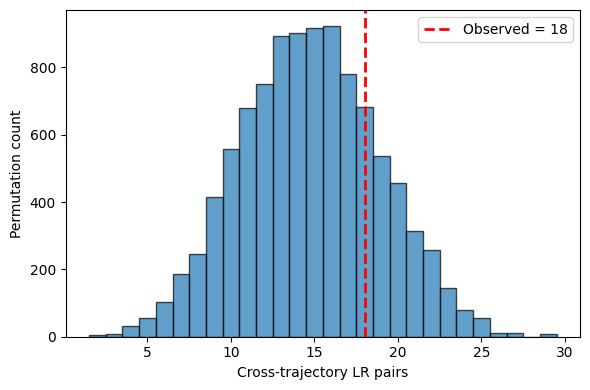

In [73]:
plt.figure(figsize=(6, 4))

plt.hist(
    null_cross,
    bins=np.arange(null_cross.min() - 0.5, null_cross.max() + 1.5, 1),
    alpha=0.7,
    edgecolor="black"
)

plt.axvline(
    observed_cross,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Observed = {observed_cross}"
)

plt.xlabel("Cross-trajectory LR pairs")
plt.ylabel("Permutation count")
plt.legend()
plt.tight_layout()
plt.show()

In [74]:
observed_same = (
    lr_sig["sender_trend"] == lr_sig["receiver_trend"]
).sum()

observed_same

n_perm = 10000

np.random.seed(42)

null_cross = []
null_same = []

for i in range(n_perm):

    # Shuffle trajectory labels across AGMs
    shuffled_trends = np.random.permutation(gam_gr["Trend"].values)

    shuffled_dict = dict(
        zip(gam_gr["Cluster"], shuffled_trends)
    )

    # Assign shuffled trajectories
    sender_shuffled = lr_sig["sender_cluster"].map(shuffled_dict)
    receiver_shuffled = lr_sig["receiver_cluster"].map(shuffled_dict)

    # Count cross and same trajectory LR pairs
    n_cross = (sender_shuffled != receiver_shuffled).sum()
    n_same = (sender_shuffled == receiver_shuffled).sum()

    null_cross.append(n_cross)
    null_same.append(n_same)
    
null_cross = np.array(null_cross)
null_same = np.array(null_same)

p_same = (
    (null_same >= observed_same).sum() + 1
) / (n_perm + 1)

p_same

print("Observed same-trajectory LR pairs:", observed_same)
print("Mean expected under null:", null_same.mean())
print("95% null interval:", np.percentile(null_same, [2.5, 97.5]))
print("Empirical p-value:", p_same)

Observed same-trajectory LR pairs: 11
Mean expected under null: 14.3031
95% null interval: [ 6. 22.]
Empirical p-value: 0.8173182681731826


In [75]:
observed_upup = (
    (lr_sig["sender_trend"] == "Increasing") &
    (lr_sig["receiver_trend"] == "Increasing")
).sum()

observed_upup

n_perm = 10000

np.random.seed(42)

null_upup = []

for i in range(n_perm):

    # Shuffle trajectory labels across AGMs
    shuffled_trends = np.random.permutation(gam_gr["Trend"].values)

    shuffled_dict = dict(
        zip(gam_gr["Cluster"], shuffled_trends)
    )

    # Assign shuffled trajectories
    sender_shuffled = lr_sig["sender_cluster"].map(shuffled_dict)
    receiver_shuffled = lr_sig["receiver_cluster"].map(shuffled_dict)

    # Count Increasing -> Increasing LR pairs
    n_upup = (
        (sender_shuffled == "Increasing") &
        (receiver_shuffled == "Increasing")
    ).sum()

    null_upup.append(n_upup)
    
null_upup = np.array(null_upup)
p_upup = (
    (null_upup >= observed_upup).sum() + 1
) / (n_perm + 1)

p_upup

print("Observed Increasing -> Increasing LR pairs:", observed_upup)
print("Mean expected under null:", null_upup.mean())
print("95% null interval:", np.percentile(null_upup, [2.5, 97.5]))
print("Empirical p-value:", p_upup)

Observed Increasing -> Increasing LR pairs: 8
Mean expected under null: 9.5328
95% null interval: [ 1. 20.]
Empirical p-value: 0.6497350264973503
